# 01 数据分析：训练集探索

**范围**：只读训练集（21,000 人）。验证集和测试集在本 notebook 中不加载。
划分由 `python -m src.data_loader` 生成（分层、种子 42、70/15/15），字段校验结果见 `data/processed/data_checks.json`。

图保存到 `reports/figures/`，分组统计保存到 `reports/eda_tables.json`，供 `reports/eda_report.md` 引用。

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import sys; sys.path.insert(0, str(ROOT))
from src.data_loader import load_split, PAY_STATUS, BILL_AMT, PAY_AMT

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TABLES = {}

# 配色：蓝 = 未违约 / 主序列，橙 = 违约；文字用中性灰
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False, "figure.dpi": 110, "savefig.dpi": 200,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", facecolor="white")

def rate_table(df, key, order=None):
    g = df.groupby(key, observed=True)["target"].agg(n="size", defaults="sum")
    if order is not None:
        g = g.reindex(order)
    g["rate"] = g["defaults"] / g["n"]
    g["ci95"] = 1.96 * np.sqrt(g["rate"] * (1 - g["rate"]) / g["n"])
    return g

def rate_bars(ax, g, title, xlabel, base, label_base=True):
    x = np.arange(len(g))
    ax.bar(x, g["rate"], width=0.68, color=BLUE, yerr=g["ci95"],
           error_kw=dict(ecolor=MUTED, elinewidth=1, capsize=2))
    ax.axhline(base, color=ORANGE, lw=1.4, ls="--")
    if label_base:
        ax.text(1.005, base, f"训练集\n平均 {base:.1%}", color=INK, fontsize=8, ha="left", va="center",
                transform=ax.get_yaxis_transform(), clip_on=False)
    for i, (r, n) in enumerate(zip(g["rate"], g["n"])):
        ax.text(i, -0.02, f"n={n:,}", ha="center", va="top", fontsize=7, color=MUTED,
                transform=ax.get_xaxis_transform())
    ax.set_xticks(x, [str(i) for i in g.index])
    ax.tick_params(axis="x", pad=14)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_ylabel("违约率"); ax.set_xlabel(xlabel); ax.set_title(title, loc="left")

tr = load_split("train")
base = tr["target"].mean()
print(tr.shape, f"违约率 {base:.2%}")

(21000, 25) 违约率 22.12%


## 1. 字段概览与特殊编码

In [2]:
desc = tr.drop(columns=["ID"]).describe().T[["mean", "std", "min", "50%", "max"]]
desc.round(1)

,mean,std,min,50%,max
LIMIT_BAL,166947.4,129648.3,10000.0,140000.0,800000.0
SEX,1.6,0.5,1.0,2.0,2.0
EDUCATION,1.9,0.8,0.0,2.0,6.0
MARRIAGE,1.6,0.5,0.0,2.0,3.0
AGE,35.4,9.2,21.0,34.0,75.0
PAY_0,-0.0,1.1,-2.0,0.0,8.0
PAY_2,-0.1,1.2,-2.0,0.0,8.0
PAY_3,-0.2,1.2,-2.0,0.0,8.0
PAY_4,-0.2,1.2,-2.0,0.0,8.0
PAY_5,-0.3,1.1,-2.0,0.0,8.0


In [3]:
special = {}
for col, codes in {"EDUCATION": [0, 5, 6], "MARRIAGE": [0]}.items():
    sub = tr[tr[col].isin(codes)]
    special[col] = {"codes": codes, "n": int(len(sub)), "default_rate": round(float(sub["target"].mean()), 4)}
pay_codes = (tr.melt(id_vars="target", value_vars=PAY_STATUS, value_name="code")
               .assign(code=lambda d: d["code"].clip(upper=3))
               .groupby("code")["target"].agg(n="size", rate="mean"))
neg_bill = int((tr[BILL_AMT] < 0).any(axis=1).sum())
special["negative_bill_customers"] = neg_bill
special["pay1_in_PAY2_6"] = int((tr[PAY_STATUS[1:]] == 1).sum().sum())
TABLES["special_codes"] = special
TABLES["pay_code_rates_all_months"] = {str(k): {"n": int(r.n), "rate": round(float(r.rate), 4)} for k, r in pay_codes.iterrows()}
print(json.dumps(special, ensure_ascii=False, indent=1)); pay_codes.round(3)

{
 "EDUCATION": {
  "codes": [
   0,
   5,
   6
  ],
  "n": 249,
  "default_rate": 0.0763
 },
 "MARRIAGE": {
  "codes": [
   0
  ],
  "n": 41,
  "default_rate": 0.0488
 },
 "negative_bill_customers": 1350,
 "pay1_in_PAY2_6": 26
}


,n,rate
code,,
-2,17039,0.185
-1,24137,0.162
0,67092,0.172
1,2702,0.339
2,13364,0.548
3,1666,0.636


## 图 1 字段分布

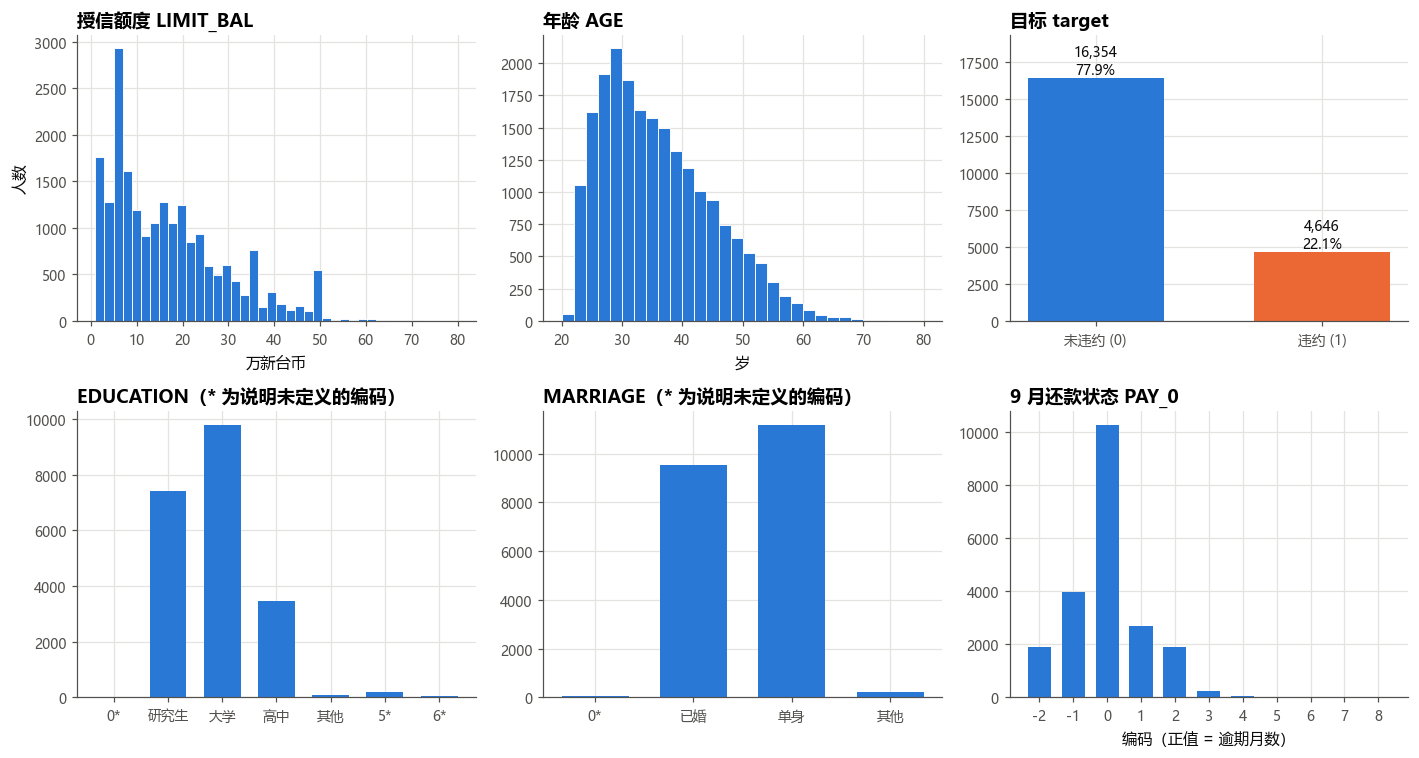

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(13, 7))
ax = axs[0, 0]; ax.hist(tr["LIMIT_BAL"] / 1e4, bins=40, color=BLUE, edgecolor="white", linewidth=0.6)
ax.set_title("授信额度 LIMIT_BAL", loc="left"); ax.set_xlabel("万新台币"); ax.set_ylabel("人数")
ax = axs[0, 1]; ax.hist(tr["AGE"], bins=range(20, 81, 2), color=BLUE, edgecolor="white", linewidth=0.6)
ax.set_title("年龄 AGE", loc="left"); ax.set_xlabel("岁")
ax = axs[0, 2]
v = tr["target"].value_counts().sort_index()
ax.bar(["未违约 (0)", "违约 (1)"], v.values, color=[BLUE, ORANGE], width=0.6)
for i, n in enumerate(v.values): ax.text(i, n, f"{n:,}\n{n/len(tr):.1%}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_title("目标 target", loc="left"); ax.set_ylim(0, v.max() * 1.18)
for ax, col, lab in [(axs[1, 0], "EDUCATION", {0: "0*", 1: "研究生", 2: "大学", 3: "高中", 4: "其他", 5: "5*", 6: "6*"}),
                     (axs[1, 1], "MARRIAGE", {0: "0*", 1: "已婚", 2: "单身", 3: "其他"})]:
    v = tr[col].value_counts().sort_index()
    ax.bar([lab[k] for k in v.index], v.values, color=BLUE, width=0.68)
    ax.set_title(f"{col}（* 为说明未定义的编码）", loc="left")
ax = axs[1, 2]
v = tr["PAY_0"].value_counts().sort_index()
ax.bar(v.index.astype(str), v.values, color=BLUE, width=0.68)
ax.set_title("9 月还款状态 PAY_0", loc="left"); ax.set_xlabel("编码（正值 = 逾期月数）")
fig.tight_layout(); save(fig, "fig1_distributions"); plt.show()

## 图 2 相关性热力图（Spearman）

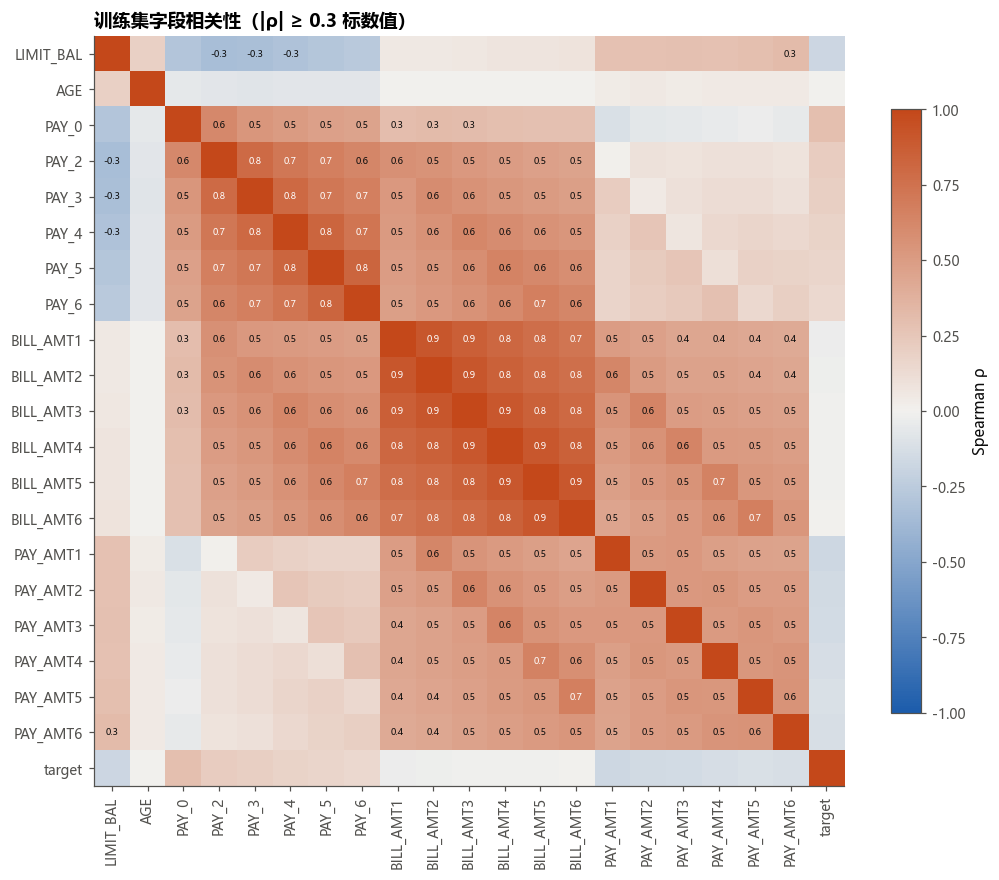

PAY_0        0.292
PAY_2        0.216
PAY_3        0.196
PAY_4        0.174
PAY_5        0.157
PAY_6        0.141
AGE          0.008
BILL_AMT6    0.001
BILL_AMT5   -0.009
BILL_AMT4   -0.011
BILL_AMT3   -0.015
BILL_AMT2   -0.019
BILL_AMT1   -0.027
PAY_AMT5    -0.116
PAY_AMT6    -0.122
PAY_AMT4    -0.127
PAY_AMT3    -0.144
PAY_AMT2    -0.154
PAY_AMT1    -0.165
LIMIT_BAL   -0.174
Name: target, dtype: float64

In [5]:
cols = ["LIMIT_BAL", "AGE"] + PAY_STATUS + BILL_AMT + PAY_AMT + ["target"]
corr = tr[cols].corr(method="spearman")
cmap = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#f2f1ee", "#c4481a"])
fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90); ax.set_yticks(range(len(cols)), cols)
ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        val = corr.iloc[i, j]
        if abs(val) >= 0.3 and i != j:
            ax.text(j, i, f"{val:.1f}", ha="center", va="center", fontsize=6,
                    color="white" if abs(val) > 0.65 else INK)
fig.colorbar(im, ax=ax, shrink=0.75, label="Spearman ρ")
ax.set_title("训练集字段相关性（|ρ| ≥ 0.3 标数值）", loc="left")
save(fig, "fig2_correlation"); plt.show()
TABLES["spearman_with_target"] = corr["target"].drop("target").round(3).sort_values(ascending=False).to_dict()
corr["target"].drop("target").sort_values(ascending=False).round(3)

## 图 3 按违约状态的账单与还款分布

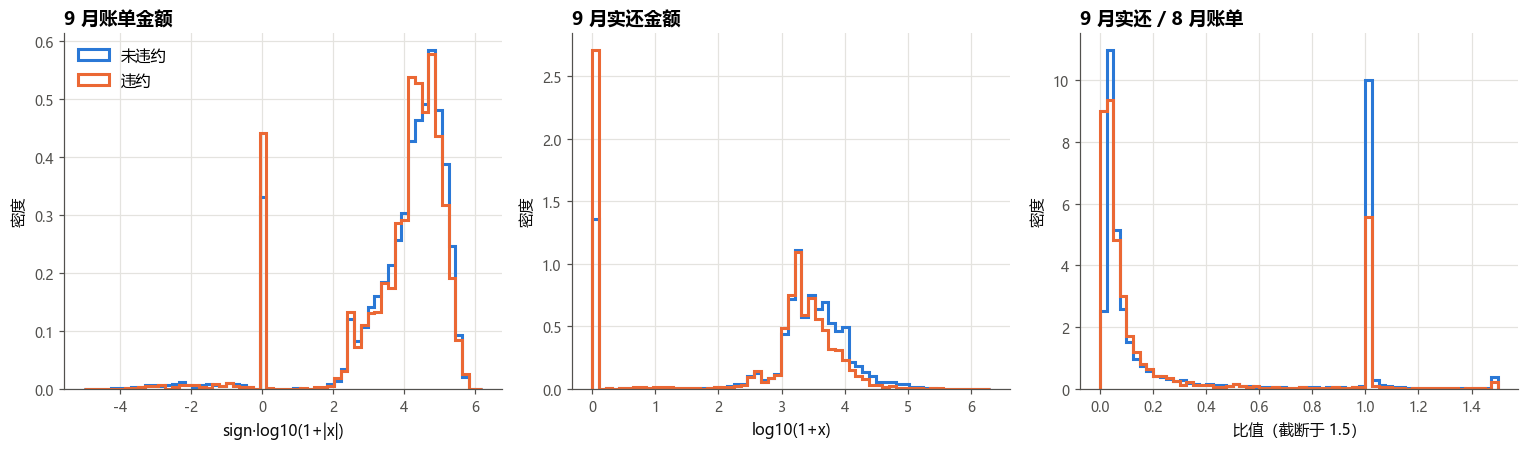

,BILL_AMT1,PAY_AMT1,PAY_RATIO1
target,,,
0,23327.0,2414.0,0.086708
1,20133.0,1600.0,0.055610


In [6]:
slog = lambda x: np.sign(x) * np.log10(1 + np.abs(x))
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
tr = tr.assign(PAY_RATIO1=np.where(tr["BILL_AMT2"] > 0, tr["PAY_AMT1"] / tr["BILL_AMT2"], np.nan))
specs = [("BILL_AMT1", "9 月账单金额", slog, np.linspace(-5, 6.2, 60), "sign·log10(1+|x|)"),
         ("PAY_AMT1", "9 月实还金额", slog, np.linspace(0, 6.3, 60), "log10(1+x)"),
         ("PAY_RATIO1", "9 月实还 / 8 月账单", lambda x: np.clip(x, 0, 1.5), np.linspace(0, 1.5, 61), "比值（截断于 1.5）")]
for ax, (col, title, f, bins, xl) in zip(axs, specs):
    for t, colr, lab in [(0, BLUE, "未违约"), (1, ORANGE, "违约")]:
        x = f(tr.loc[tr["target"] == t, col].dropna())
        ax.hist(x, bins=bins, density=True, histtype="step", lw=2, color=colr, label=lab)
    ax.set_title(title, loc="left"); ax.set_xlabel(xl); ax.set_ylabel("密度")
axs[0].legend(loc="upper left")
fig.tight_layout(); save(fig, "fig3_bill_by_target"); plt.show()

med = tr.groupby("target")[["BILL_AMT1", "PAY_AMT1", "PAY_RATIO1"]].median()
TABLES["median_by_target"] = {c: {str(k): round(float(v), 3) for k, v in med[c].items()} for c in med}
tr = tr.drop(columns="PAY_RATIO1"); med

## 图 4 按授信额度分组的违约率

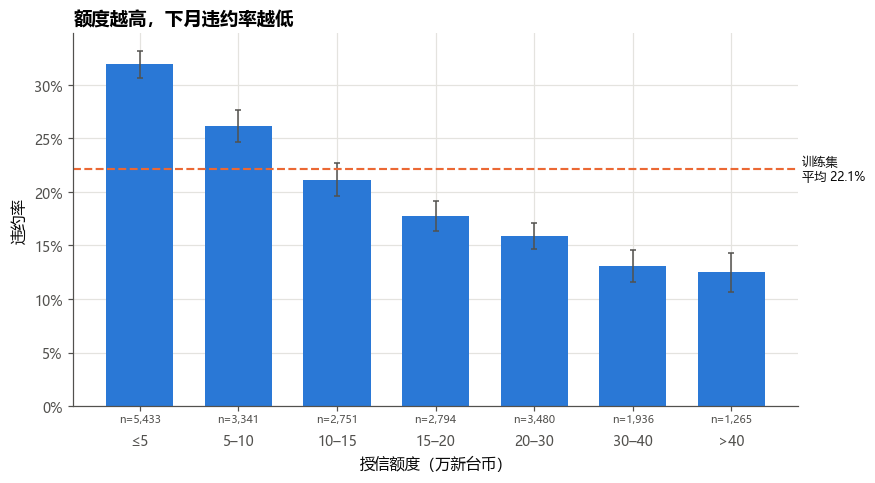

,n,defaults,rate,ci95
band,,,,
≤5,5433,1732,0.319,0.012
5–10,3341,872,0.261,0.015
10–15,2751,581,0.211,0.015
15–20,2794,496,0.178,0.014
20–30,3480,554,0.159,0.012
30–40,1936,253,0.131,0.015
>40,1265,158,0.125,0.018


In [7]:
edges = [0, 50_000, 100_000, 150_000, 200_000, 300_000, 400_000, 1_000_001]
labels = ["≤5", "5–10", "10–15", "15–20", "20–30", "30–40", ">40"]
g = rate_table(tr.assign(band=pd.cut(tr["LIMIT_BAL"], edges, labels=labels, right=True)), "band", labels)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
rate_bars(ax, g, "额度越高，下月违约率越低", "授信额度（万新台币）", base)
save(fig, "fig4_rate_by_limit"); plt.show()
TABLES["rate_by_limit"] = g.round(4).reset_index().astype({"band": str}).to_dict("records"); g.round(3)

## 图 5 按 9 月逾期状态分组的违约率

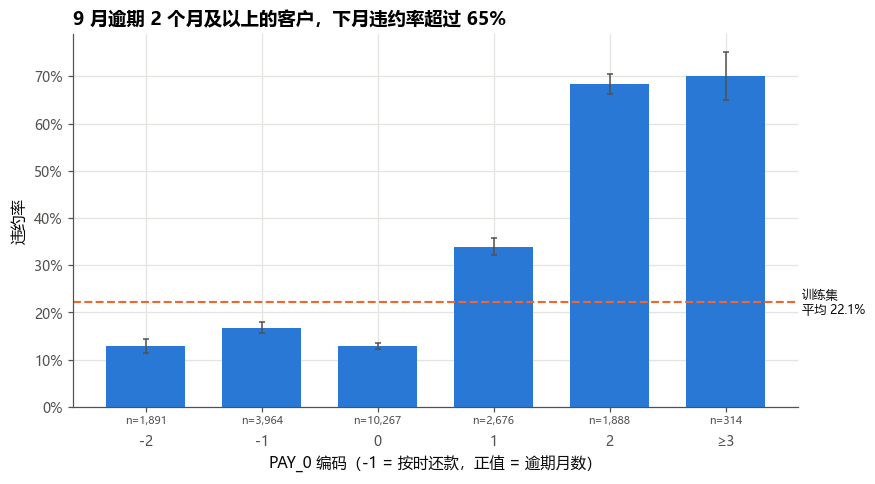

,n,defaults,rate,ci95
k,,,,
-2,1891,245,0.130,0.015
-1,3964,665,0.168,0.012
0,10267,1317,0.128,0.006
1,2676,909,0.340,0.018
2,1888,1290,0.683,0.021
≥3,314,220,0.701,0.051


In [8]:
order = ["-2", "-1", "0", "1", "2", "≥3"]
key = tr["PAY_0"].clip(upper=3).map(lambda v: "≥3" if v == 3 else str(v))
g = rate_table(tr.assign(k=key), "k", order)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
rate_bars(ax, g, "9 月逾期 2 个月及以上的客户，下月违约率超过 65%", "PAY_0 编码（-1 = 按时还款，正值 = 逾期月数）", base)
save(fig, "fig5_rate_by_pay0"); plt.show()
TABLES["rate_by_pay0"] = g.round(4).reset_index().to_dict("records"); g.round(3)

## 图 6 近六个月逾期月份数与违约率（特征工程预览）

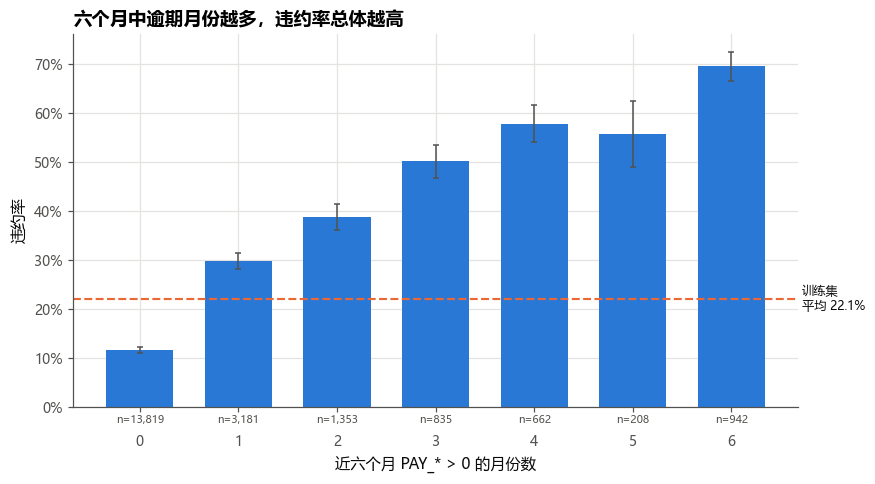

,n,defaults,rate,ci95
k,,,,
0,13819,1602,0.116,0.005
1,3181,946,0.297,0.016
2,1353,525,0.388,0.026
3,835,419,0.502,0.034
4,662,383,0.579,0.038
5,208,116,0.558,0.067
6,942,655,0.695,0.029


In [9]:
n_late = (tr[PAY_STATUS] > 0).sum(axis=1)
g = rate_table(tr.assign(k=n_late), "k", list(range(7)))
fig, ax = plt.subplots(figsize=(8.5, 4.4))
rate_bars(ax, g, "六个月中逾期月份越多，违约率总体越高", "近六个月 PAY_* > 0 的月份数", base)
save(fig, "fig6_rate_by_late_months"); plt.show()
TABLES["rate_by_late_months"] = g.round(4).reset_index().to_dict("records"); g.round(3)

## 图 7 额度使用率与违约率

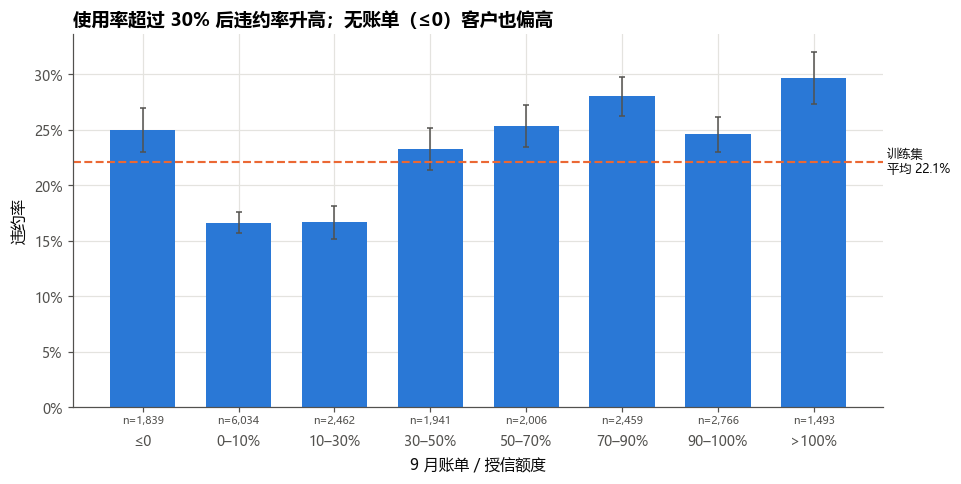

,n,defaults,rate,ci95
k,,,,
≤0,1839,460,0.250,0.020
0–10%,6034,1004,0.166,0.009
10–30%,2462,410,0.167,0.015
30–50%,1941,452,0.233,0.019
50–70%,2006,508,0.253,0.019
70–90%,2459,689,0.280,0.018
90–100%,2766,680,0.246,0.016
>100%,1493,443,0.297,0.023


In [10]:
util = tr["BILL_AMT1"] / tr["LIMIT_BAL"]
edges = [-np.inf, 0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0, np.inf]
labels = ["≤0", "0–10%", "10–30%", "30–50%", "50–70%", "70–90%", "90–100%", ">100%"]
g = rate_table(tr.assign(k=pd.cut(util, edges, labels=labels)), "k", labels)
fig, ax = plt.subplots(figsize=(9.5, 4.4))
rate_bars(ax, g, "使用率超过 30% 后违约率升高；无账单（≤0）客户也偏高", "9 月账单 / 授信额度", base)
save(fig, "fig7_rate_by_utilization"); plt.show()
TABLES["rate_by_utilization"] = g.round(4).reset_index().astype({"k": str}).to_dict("records"); g.round(3)

## 图 8 人口属性分组违约率（供公平性审计参考）

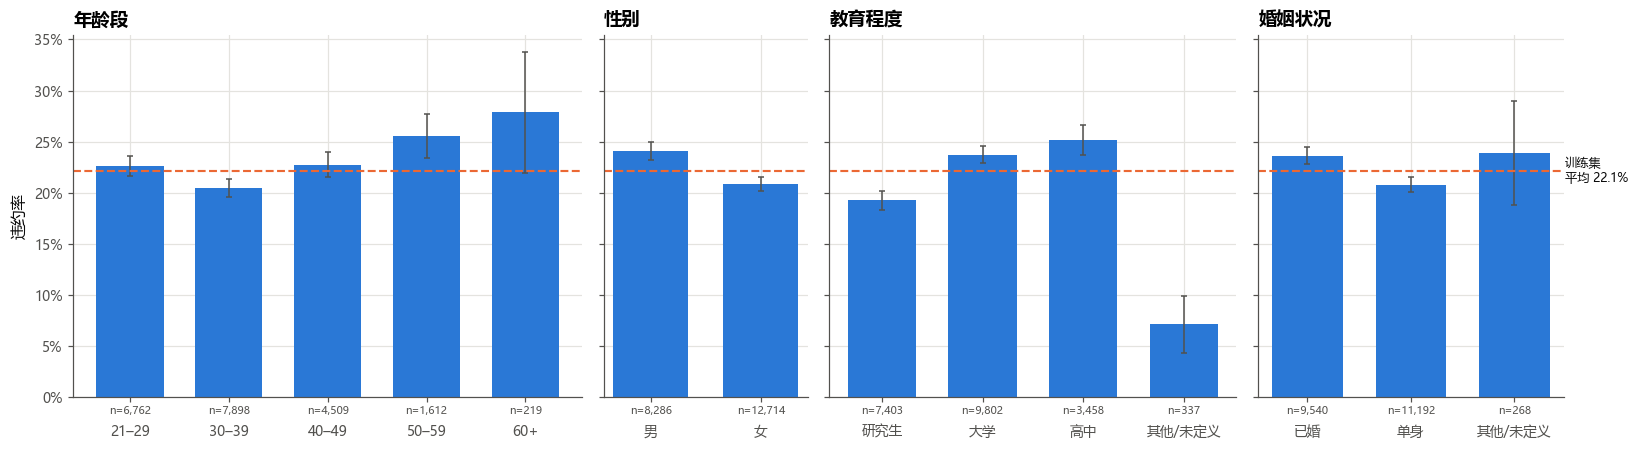

In [11]:
age_lab = ["21–29", "30–39", "40–49", "50–59", "60+"]
age = pd.cut(tr["AGE"], [20, 29, 39, 49, 59, 100], labels=age_lab)
sex = tr["SEX"].map({1: "男", 2: "女"})
edu = tr["EDUCATION"].map({1: "研究生", 2: "大学", 3: "高中"}).fillna("其他/未定义")
mar = tr["MARRIAGE"].map({1: "已婚", 2: "单身"}).fillna("其他/未定义")
fig, axs = plt.subplots(1, 4, figsize=(15, 4.2), sharey=True,
                        gridspec_kw=dict(width_ratios=[5, 2, 4, 3]))
groups = [("年龄段", age, age_lab), ("性别", sex, ["男", "女"]),
          ("教育程度", edu, ["研究生", "大学", "高中", "其他/未定义"]), ("婚姻状况", mar, ["已婚", "单身", "其他/未定义"])]
TABLES["rate_by_demographics"] = {}
for ax, (name, k, order) in zip(axs, groups):
    g = rate_table(tr.assign(k=k), "k", order)
    rate_bars(ax, g, name, "", base, label_base=(ax is axs[-1]))
    if ax is not axs[0]: ax.set_ylabel("")
    TABLES["rate_by_demographics"][name] = g.round(4).reset_index().astype({"k": str}).to_dict("records")
fig.tight_layout(); save(fig, "fig8_rate_by_demographics"); plt.show()

## 保存分组统计

In [12]:
TABLES["n_train"] = int(len(tr)); TABLES["base_rate"] = round(float(base), 4)
(ROOT / "reports" / "eda_tables.json").write_text(json.dumps(TABLES, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
print("已写入 reports/eda_tables.json；图：", sorted(p.name for p in FIG.glob("fig*.png")))

已写入 reports/eda_tables.json；图： ['fig1_distributions.png', 'fig2_correlation.png', 'fig3_bill_by_target.png', 'fig4_rate_by_limit.png', 'fig5_rate_by_pay0.png', 'fig6_rate_by_late_months.png', 'fig7_rate_by_utilization.png', 'fig8_rate_by_demographics.png']
